<p style="text-align: right; margin: 0; line-height: 0;"><img width="100px" height="auto" src="../../.admin/img/eth_logo.png"></p>

<h1 style="text-align: center;">02 Data Communication</h1>
<hr>


## **2. Source Coding**


<div class="alert alert-light">

  **Name:** Stefan Sykes
  
  **Matriculation Number:** 11-250-693
  
</div>



### 2.1 Introduction

One of our earlier notebooks, [**Entropy**](../01_Data_and_Signals/01.5_Entropy.ipynb), introduced entropy as a measure of the average information contained in a source. It also showed that entropy, measured in bit per source symbol when using a base-2 logarithm, provides a lower bound on the average encoded length achievable by lossless source coding. Predictable source data contains patterns and statistical redundancy that a source code may exploit.

**Source coding** transforms source symbols into a sequence of bits suitable for storage, processing, or transmission. Its purpose is to describe the source efficiently by using fewer bits where the source statistics allow it. The resulting reduction in data size is commonly called **data compression**.

Source coding can be **lossless** or **lossy**. Lossless source coding preserves all information needed to reconstruct the original data exactly. Lossy source coding permits controlled differences between the original and reconstructed data when exact recovery is unnecessary, often allowing a much smaller encoded size.

Efficient source coding is particularly important in mobile computing. Digital images, audio, video, sensor streams, and application data can require substantial storage and transmission capacity. Wireless channels have finite bandwidth, mobile devices have limited energy and memory, and many applications must deliver data within strict latency limits. Reducing the encoded size can shorten transmission time and radio activity, conserve storage, and make it possible to serve more users with the same communication capacity. Source coding itself also requires computation, however, so the smallest encoded size is not automatically the most energy-efficient or fastest choice.

Source coding supports everyday services such as media streaming, cloud backups, software distribution, and mobile messaging. Different sources require different methods because they contain different forms of redundancy and tolerate different kinds of distortion. Text and general files commonly use lossless methods, while images, audio, and video may use either lossless or lossy methods depending on the required fidelity. Huffman and arithmetic coding exploit symbol probabilities, whereas modern media codecs also exploit spatial, temporal, and perceptual structure. Across these approaches, the central objective remains the same: represent the useful information with fewer bits while respecting the application's requirements.

This notebook connects the entropy limit to practical source-coding methods. It compares lossless and lossy source coding, demonstrates how predictable data can require fewer bits, and explores how Huffman coding assigns shorter codewords to frequent symbols and longer codewords to rare symbols. The objective is to understand how a source encoder reduces the number of bits before the encoded data is passed to the next stage of a communication system.

#### 2.1.1 First Experiment: Two Binary Sources

The preceding Redundancy notebook compared two sources. Source A emits independent random bits, while Source B emits the predictable sequence `0 1 0 1 ...`. Both sources contain equally many zeros and ones, so each has a single-symbol entropy of $H(X_n)=1$ bit. However, only Source B has strong sequential redundancy.

The following experiment generates one million bits from each source. The bits are packed into bytes so that eight source bits occupy one byte in each file. Both uncompressed binary files therefore have exactly the same size.

Each binary file is compressed into its own ZIP file. Comparing the two ZIP sizes shows whether a general-purpose compressor can exploit the predictable structure in the source. The files are written to the folder `compression_example_files`.


Source A: independent
  Binary file: 125,000 bytes
  ZIP file:    125,176 bytes
  ZIP/original ratio: 1.0014

Source B: alternating
  Binary file: 125,000 bytes
  ZIP file:    285 bytes
  ZIP/original ratio: 0.0023



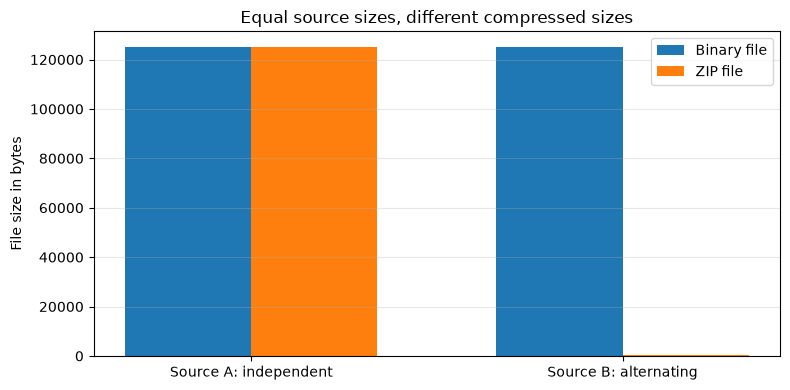

In [1]:
from pathlib import Path
import zipfile
import numpy as np
import matplotlib.pyplot as plt

number_of_bits = 1_000_000
output_directory = Path("compression_example_files")
output_directory.mkdir(exist_ok=True)

rng = np.random.default_rng(7)
source_a = rng.integers(0, 2, size=number_of_bits, dtype=np.uint8)
source_b = np.arange(number_of_bits, dtype=np.uint8) % 2

sources = {
    "Source A: independent": source_a,
    "Source B: alternating": source_b,
}

results = []
for label, bits in sources.items():
    short_name = "source_a_random" if "A:" in label else "source_b_alternating"
    binary_path = output_directory / f"{short_name}.bin"
    zip_path = output_directory / f"{short_name}.zip"

    binary_path.write_bytes(np.packbits(bits).tobytes())
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED,
                         compresslevel=9) as archive:
        archive.write(binary_path, arcname=binary_path.name)

    original_size = binary_path.stat().st_size
    zip_size = zip_path.stat().st_size
    results.append((label, original_size, zip_size))

for label, original_size, zip_size in results:
    ratio = zip_size / original_size
    print(f"{label}")
    print(f"  Binary file: {original_size:,} bytes")
    print(f"  ZIP file:    {zip_size:,} bytes")
    print(f"  ZIP/original ratio: {ratio:.4f}\n")

labels = [label for label, original_size, zip_size in results]
original_sizes = [original_size for label, original_size, zip_size in results]
zip_sizes = [zip_size for label, original_size, zip_size in results]
positions = np.arange(len(labels))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(positions - width/2, original_sizes, width, label="Binary file")
ax.bar(positions + width/2, zip_sizes, width, label="ZIP file")
ax.set_xticks(positions, labels)
ax.set_ylabel("File size in bytes")
ax.set_title("Equal source sizes, different compressed sizes")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Both binary files contain 125,000 bytes. The ZIP file for Source A is approximately the same size as the original and may be slightly larger because the random data provides almost no pattern to exploit and the archive adds metadata. The ZIP file for Source B is much smaller because the alternating bits become the repeated byte pattern `01010101`.

This result illustrates why single-symbol entropy is not sufficient to describe compressibility. Both sources have $H(X_n)=1$ bit, but only Source B has strong sequential redundancy that compression can exploit.


### 2.2 Interactive Example: Entropy of Text

To see how symbol probabilities affect source coding, the interactive example below estimates the symbol entropy of a text from its observed character frequencies. Each distinct character, including a space, is treated as one source symbol. Change the text to compare inputs with different character distributions.

In [2]:
import ipywidgets as widgets
from IPython.display import display
from collections import Counter
import math


def entropy(text):
    freq = Counter(text)
    N = len(text)
    return -sum((count/N) * math.log2(count/N) for count in freq.values())

sample = "hello hello hello mobile computing"


def update_entropy(text):
    print("Text:", text)
    print("Entropy:", round(entropy(text), 3), "bit per symbol")

text_widget = widgets.Text(value=sample, description='Sample Text:')
widgets.interactive(update_entropy, text=text_widget)


interactive(children=(Text(value='hello hello hello mobile computing', description='Sample Text:'), Output()),…

The output is an empirical symbol-entropy estimate in bit per character because each character is treated as one symbol. A repetitive input such as `aaaaabbbb` has an uneven character distribution and therefore a lower entropy estimate. An input such as `abcdefghi`, in which the observed characters are all equally frequent, has a higher estimate and offers less opportunity for this kind of statistical compression. For comparison, standard ASCII defines 7-bit character values, while text is commonly stored in byte-oriented encodings that use at least 8 bit for many characters.

This calculator considers only how often each character occurs. It does not consider character order or sequential predictability. A random binary string and an alternating string such as `abababab` can therefore both have a symbol entropy of 1 bit per character, even though the alternating string is completely predictable after its first character.

This experiment does not yet create a compressed representation. It measures the limit that motivates the coding method introduced in Section 2.3. Huffman coding uses short codewords for frequent symbols and longer codewords for rare symbols, reducing the average encoded length toward the entropy bound.


### 2.3 Practical Method: Huffman Encoding  

So far, we have seen that entropy provides a lower bound on the average encoded length that lossless source coding can approach under an assumed source model. The next question is: how do we design a practical code that approaches this bound?  

One of the most widely used techniques is **Huffman encoding**, introduced by David Huffman in 1952. It is a **lossless compression algorithm** that assigns shorter binary codes to frequent symbols and longer codes to rare ones. The result is a **prefix-free code**: no symbol’s code is the prefix of another, so decoding is always unambiguous.  

The core idea is simple:  
1. Count how often each symbol occurs (its frequency).  
2. Build a binary tree by repeatedly merging the two least frequent symbols.  
3. Assign binary codes to symbols by following paths in the tree (left = 0, right = 1).  

This way, the average number of bits per symbol approaches the source entropy. Huffman coding is the foundation of many compression formats, including **ZIP**, **PNG**, and parts of **MP3**.  
 

To make the process concrete, let’s look at this GIF, which shows Huffman coding applied to a random text :  

<center>
<img src="../../.admin/notebooks/picture/Huffman_huff_demo.gif" 
     alt="Huffman Coding Demonstration" 
     width="50%" 
     style="filter: grayscale(50%);">
<p style="text-align: center; font-size: 0.9em;">
Source: <a href="https://upload.wikimedia.org/wikipedia/commons/a/ac/Huffman_huff_demo.gif">Wikimedia Commons</a> · License: CC BY-SA 3.0
</p>
</center>
 

Watch carefully:  
- At the start, each character is listed with its frequency.  
- The algorithm repeatedly merges the two least frequent nodes into a new parent node.  
- When only one node remains (the root), the tree is complete.  
- Traversing the tree gives us the codes: left edge = `0`, right edge = `1`.  

The final output assigns short codes to frequent letters (like `a` and `t`) and longer codes to rare ones. This reduces the total size of the encoded text compared to using a fixed-length scheme such as ASCII.  




The power of Huffman coding comes from exploiting **non-uniform symbol frequencies**. If all symbols are equally likely, Huffman coding cannot benefit from assigning shorter codewords to more frequent symbols because no symbol is more frequent than another. This does not prove that the complete source is incompressible. The source may still contain sequential, spatial, or other predictable structure that a different coding method can exploit, as the alternating binary source in Section 2.1.1 demonstrated. Real-world data often contains both unequal symbol frequencies and other forms of redundancy:  
- In English text, letters like `e`, `t`, and `a` are far more common than `z` or `q`.  
- In sensor data, some values repeat much more often than others.  

By matching code lengths to probabilities, Huffman coding makes efficient use of bits and gets us close to the entropy bound.  


### 2.4 Lossless and Lossy Compression

Lossless compression preserves all information needed to recover the original data exactly. It is required when any change could alter meaning or behavior, as with program files, financial records, scientific measurements, or text documents. ZIP archives, PNG images, and FLAC audio are familiar examples. Their achievable compression depends on the redundancy present in the source and cannot surpass the entropy limit on average under the assumed source model.

Lossy compression permits controlled differences between the original and reconstructed data in exchange for a greater reduction in size. It is useful when exact reconstruction is unnecessary and when the discarded detail has little effect on the intended use. JPEG images and perceptual audio or video codecs exploit properties of human perception to remove or simplify information that is less noticeable. The acceptable amount of loss depends on the application, so a setting suitable for entertainment media may be unacceptable for medical images, measurements, program files, or financial data.

To see lossy compression in action, we’ll take a sample image from `scikit-image` and save it at different JPEG quality levels. This will let us compare how reducing quality affects both the file size and the visible details of the image.  


In [3]:
%pip install scikit-image


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


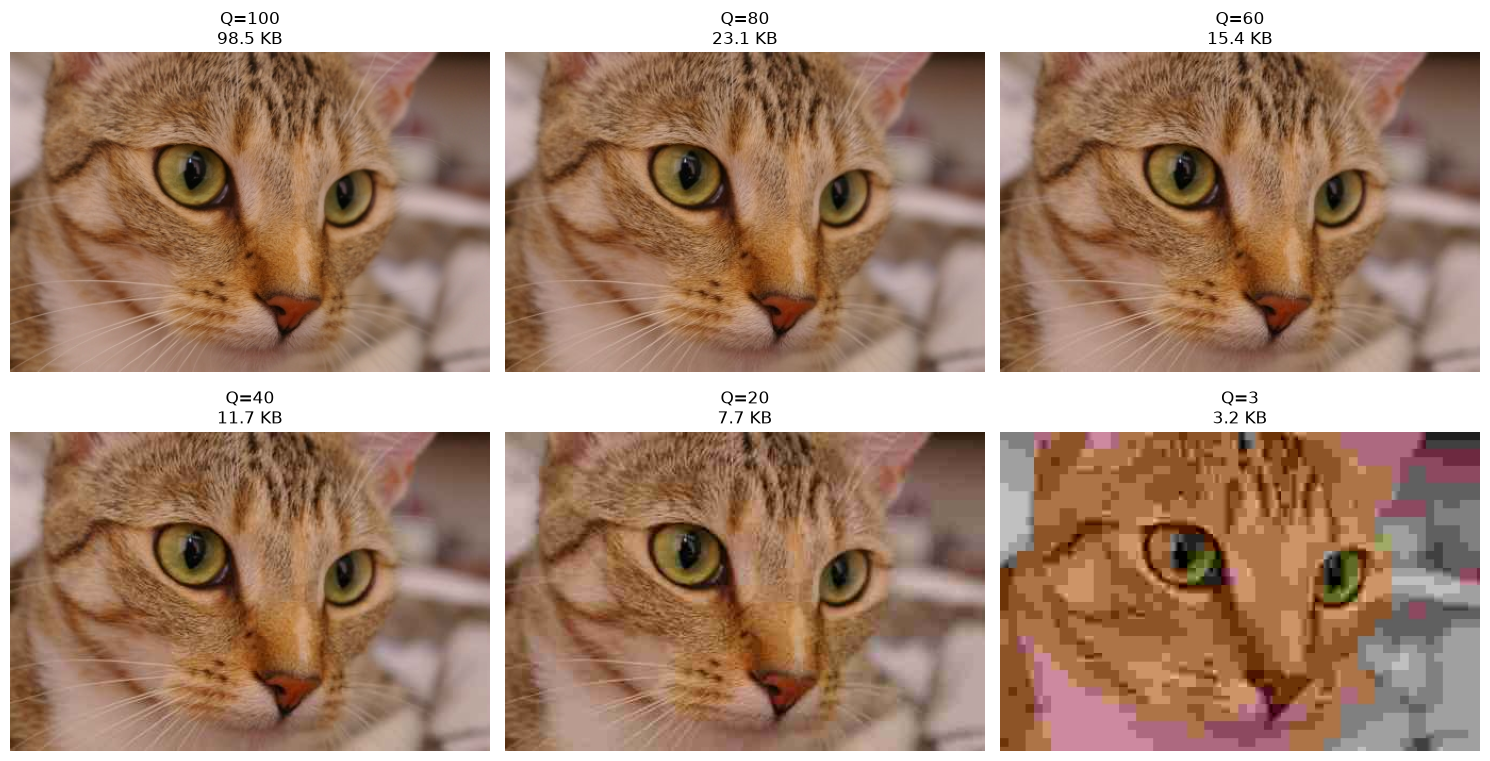

In [4]:
from skimage import data
from PIL import Image
import io
import matplotlib.pyplot as plt

# Load a sample image (cat)
cat = data.chelsea()
img = Image.fromarray(cat)

qualities = [100, 80, 60, 40, 20, 3]
compressed_images = []
sizes_kb = []

for q in qualities:
    # Save into a memory buffer instead of disk
    with io.BytesIO() as buffer:
        img.save(buffer, format="JPEG", quality=q)
        sizes_kb.append(buffer.tell() / 1024)

        # Copy the decoded image before closing the buffer
        buffer.seek(0)
        with Image.open(buffer) as compressed:
            compressed_images.append(compressed.copy())

# Plot the six quality levels in two rows
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, q, im, s in zip(
    axes.flat, qualities, compressed_images, sizes_kb
):
    ax.imshow(im)
    ax.set_title(f"Q={q}\n{s:.1f} KB")
    ax.axis("off")

plt.tight_layout()
plt.show()

Notice how the image changes as the JPEG quality decreases through **Q=100, 80, 60, 40, 20, and 3**. The first row shows the higher-quality settings, where the cat remains detailed but the file size gradually decreases. In the second row, the loss of fine detail becomes increasingly visible. At **Q=20**, compression artifacts are easier to recognize, and at **Q=3**, strong blockiness, blurring, and loss of detail are clearly visible. JPEG is still a lossy method at Q=100, even when visual differences are difficult to notice.

The experiment demonstrates the fundamental trade-off in lossy source coding: **reducing the encoded size can reduce visual quality**. In mobile computing, an appropriate quality setting can save bandwidth, storage, transmission time, and battery power while keeping the image suitable for its intended use. Streaming services apply the same principle when they adapt media quality to the available network capacity.


### 2.5 Trade-Offs

A source-coding method must balance encoded size, reconstruction quality, computation, and latency. Lossless methods preserve the source exactly but usually produce larger outputs than lossy methods. Lossy methods can produce much smaller outputs, but they introduce distortion. More advanced methods may reduce the size further while requiring additional processing time and energy. Real-time applications must also avoid coding methods that introduce excessive delay.

The appropriate balance depends on the application. Bank transactions, program files, and many medical records require lossless source coding because exact reconstruction matters most. Streaming media can use lossy source coding because modest distortion may be acceptable in exchange for a smaller encoded size. Video calls additionally require low delay, so a lightweight codec may be preferable to a slower method that produces a slightly smaller output.

There is therefore no universally best source-coding method. Engineers choose a method by balancing integrity, efficiency, latency, energy consumption, and the intended user experience.


### 2.6 Bridge to Channel Coding

Source coding reduces the number of bits needed to describe the source. Before those bits are transmitted through a physical channel, a communication system may deliberately add structured redundancy that helps the receiver detect or correct errors. The next notebook introduces **channel coding** and explains why adding this carefully designed redundancy can improve reliability.


---

### 2.7 Hands-On Exercise  


<div class="alert alert-block alert-info">Fill in your responses and save this notebook. See the <a href="../../03_Assignments/Submission-Guidelines.md">submission guidelines</a> for how to submit your work.</div>


**Use the interactive entropy calculator in Section 2.2 to create four example strings, each containing 10 to 20 letters. Create two strings with an entropy close to 1 bit per character and two strings with an entropy close to 0 bit per character. For the examples close to 1, use only two different letters, so that 1 bit per character is the maximum possible entropy. Record each string and its calculated entropy, then briefly explain how its letter frequencies produce a high or low entropy.**  

- High entropy (close to 1): both letters appear equally often, or almost equally often. The next letter is hard to guess, so each letter carries a lot of information.
- Low entropy (close to 0): almost every letter is `a`. The next letter is easy to guess, so each letter carries very little information. If all letters are the same, the entropy is exactly $0$.

| String | Letters | Entropy (bit per character) |
|---|---|---|
| `ababababab` | 10 | $1.0$ |
| `aaaaabbbbbb` | 11 | $0.994$ |
| `aaaaaaaaaaaaaaaaaaaa` | 20 | $0.0$ |
| `aaaaaaaaaaaaaaaaaaab` | 20 | $0.286$ |

**Using the interactive entropy calculator in Section 2.2, create a string of exactly 10 letters that has the maximum possible empirical entropy. You may choose any letters. Record your string and its calculated entropy, then explain why its letter-frequency distribution produces the maximum value.**  

| String | Letters | Entropy (bit per character) |
|---|---|---|
| `abcdefghij` | 10 | $3.322$ |

Every letter is different, so each letter appears exactly once, with probability $1/10$. This is the most even distribution possible for 10 letters. No letter is more likely than another, so the next letter is as hard to guess as possible, and the entropy is at its maximum.

**What is the difference between lossless and lossy compression? Can you give an example of each?**  

- Lossless compression makes the data smaller without losing anything. After decompression, the data is exactly the same as the original.
Example: a ZIP file.
- Lossy compression makes the data much smaller by throwing away details that people barely notice. After decompression, the data is close to the original, but not identical.
Example: a JPEG photo.

**Why does Huffman coding assign shorter codes to more frequent symbols?**  

Symbols that appear often are used many times, so giving them short codes saves many bits. Rare symbols appear only a few times, so their longer codes cost little in total. Overall, the message needs fewer bits. It works like abbreviations: we shorten words we use often ("info" instead of "information"), not words we rarely use.


**What is the entropy of a source, and why does it matter for source coding?**  

Entropy measures how much information a source contains on average, in bit per symbol. The more predictable the source, the lower its entropy. It matters because it is the lower limit for lossless compression: on average, you cannot encode the source with fewer bits per symbol than its entropy. It tells us how much a source can be compressed at best.

**In the image compression experiment, at which JPEG quality level did you first notice visible artifacts?**  

At $Q=40$, the first artifacts became visible: the fine hair on the cat's nose was no longer as sharp. At $Q=20$, blocks and blur were clearly visible, and at $Q=3$ the image was very blocky and many details were lost.

**Why is lossy compression often acceptable for audio and video, but not for bank transactions or program files?**  

In audio and video, small losses are hardly noticeable. The song or film still sounds and looks fine. In bank transactions and program files, every bit matters. One changed digit could turn CHF 100 into CHF 900, and one changed bit can make a program crash. That's why they must be compressed losslessly.

**What is the trade-off between compression ratio and computational complexity? How does this affect mobile devices?**  

Stronger compression makes files smaller, but it usually needs more calculation. For mobile devices, this matters in two ways:
- Smaller files need less storage and less time to send, and sending less saves battery.
- More calculation takes time and also uses battery.

**In wireless communication, why might a system choose a lower-quality (lossy) compression setting for video calls under poor network conditions?**  

With a poor network, less data can be sent per second. A high-quality video would not arrive in time, so the call would freeze or lag. A lower quality setting makes the video smaller, so it still arrives on time. In a video call, a smooth conversation matters more than a sharp picture.



**OPTIONAL: Did you read through and understand all the tasks in this Notebook? Are there any shortcomings, missing parts, or sections that should be improved?**

 (please help the team by telling us what part was not understood, and we will work on it)